## 1 — Setup, Styling & Constants

In [ ]:
from __future__ import annotations

import re
import sys
import warnings
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from cycler import cycler
import math
import nltk
from matplotlib.colors import LinearSegmentedColormap

def ensure_nltk_resources():
    resources = [
        "tokenizers/punkt",
        "tokenizers/punkt_tab",
        "corpora/stopwords",
        "corpora/wordnet",
        "corpora/omw-1.4"
    ]
    for r in resources:
        try:
            nltk.data.find(r)
        except LookupError:
            nltk.download(r.split("/", 1)[1])

ensure_nltk_resources()


# --- APA 7 palette (BrBG diverging; see apa7-plotting skill) ---
BRBG_HEX = ["#543005", "#8c510a", "#bf812d", "#dfc27d", "#f6e8c3",
            "#f5f5f5", "#c7eae5", "#80cdc1", "#35978f", "#01665e", "#003c30"]
APA_DIVERGING = LinearSegmentedColormap.from_list("apa_brbg", BRBG_HEX, N=256)


mpl.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Helvetica", "Arial", "DejaVu Sans"],
    "font.size": 10,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "svg.fonttype": "none",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

# --- Fixed colors ---
RESTING_AGG_COLOR = "#2171b5"    
BREATHING_AGG_COLOR = "#d94801"      
MEQ_COLOR = "#8c510a"             

# --- Analysis constants ---

# NOTE (synthetic data): EXCLUDED_VPS and FACE_ID_CORRECTIONS are placeholders that
# match the synthetic dataset The original annoation data are not published (participant privacy).

EXCLUDED_VPS = ["SYN900"]
FACE_ID_CORRECTIONS = {"SYNO25": "SYN025"}
FPS = 50                                     


[nltk_data] Downloading package wordnet to
[nltk_data]     /Users/macmini_armin/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     /Users/macmini_armin/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


In [29]:
# check versions
import nltk, sys
print(sys.executable, sys.version.split()[0], nltk.__version__)
from nltk.corpus import wordnet as wn
print(wn.get_version())

/opt/miniconda3/bin/python 3.12.2 3.9.1
3.0


## 2 — Text filtering & tokenizer


In [30]:
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

# Additonal manually selected words to drop on top of nltk english stopwords
exclude_words = [
    "like", "yeah", "really", "know", "think", "also", "kind", "bit",
    "okay", "something", "little", "go", "time", "one", "back", "could",
    "going", "point", "um", "maybe", "lot", "session", "still", "would",
    "say", "oh", "actually", "even", "first", "part", "good","coming", 
    "right", "much", "way", "get", "want", "almost", "two", "came", "thing",
    "see", "interesting", "three", "yes", "nice", "started", "definitely",
    "sometimes", "life", "thinking", "went", "already", "everything", "whole",
    "always", "happening", "come", "sure", "mean", "put", "end", "ca", 
    "ah", "gpba", "different", "need", "wanted", "make", "quite", "pillow", 
    "sort", "later", "well", "third", "four", "five", "feel","eye", "state", 
    "take", "usually", "period", "somewhere", "somehow", "things", "let", "said",
    "breathe", "breath", "body"
]

# STOP now only combines NLTK stop words and your manual exceptions
STOP = set(stopwords.words("english")) | set(exclude_words)
_lemmatizer = WordNetLemmatizer()

# WordNet misses a few high-frequency irregulars
_IRREGULAR = {"felt": "feel",
              "peacefullness": "peaceful",
              "peacefulness": "peaceful",
              "deeper": "deep",
              }


def _lemma(w: str) -> str:
    """Collapse inflections to a base form (noun-plural then verb-tense)."""
    if w in _IRREGULAR:
        return _IRREGULAR[w]
    return _lemmatizer.lemmatize(_lemmatizer.lemmatize(w, pos="n"), pos="v")




def tokens_for(text: str) -> list[str]:
    """lowercase -> tokenize -> drop stopwords/filler on RAW token -> lemmatize -> re-check."""
    out: list[str] = []
    for w in word_tokenize(str(text).lower()):
        if not w.isalpha() or w in STOP:
            continue
        lemma = _lemma(w)
        if lemma not in STOP:
            out.append(lemma)
    return out


# Bereinigte Print-Ausgabe
print(f"STOP words: {len(STOP)} (nltk {len(set(stopwords.words('english')))} "
      f"+ custom {len(set(exclude_words))})")
print("sanity:", tokens_for("I really felt how the touch helped me moving, yeah."))


STOP words: 289 (nltk 198 + custom 91)
sanity: ['touch', 'help', 'move']


## Set paths

In [ ]:
# Load synthetic data
# NOTE (synthetic data): paths point to the synthetic stand-in dataset
# Replace with the real input folder to reproduce the analysis on the original data.

REPO = next((b for b in [Path.cwd(), *Path.cwd().parents] if (b / ".git").exists()), Path.cwd())

ANNOT_PATH = REPO / "input" / "data_annotations_synthetic" / "transcripts_bw.csv"
ASC_PATH   = REPO / "input" / "data_annotations_synthetic" / "ASC_all.csv"

# Phase-data for binding transcripts to phases
phase_base = REPO / "input" / "data_annotations_synthetic" / "session_phases"
phase_files = sorted(phase_base.glob("**/phase_intervals*.csv"))

# Output
OUT_DIR = Path.cwd() / "output" / "wordclouds"
OUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Annotation csv path {ANNOT_PATH}")
print(f"Phasen: {len(phase_files)} csv found")

print("ASC csv path:", ASC_PATH)
print("Output path:", OUT_DIR)


Annotation csv path /Users/macmini_armin/Lokal/Git-Reposetories/Paper_RESET_github/input/data_annotations_synthetic/transcripts_bw.csv
Phasen: 30 csv found
ASC csv path: /Users/macmini_armin/Lokal/Git-Reposetories/Paper_RESET_github/input/data_annotations_synthetic/ASC_all.csv
Output path: /Users/macmini_armin/Lokal/Git-Reposetories/Paper_RESET_github/code/annotations_word-clouds/output/wordclouds


## Load annotations

In [32]:
# 1. VP-ID normalization and exclusion of VPs
def norm_vp(s: pd.Series) -> pd.Series:
    """Canonicalize VP-id column and fix known typos."""
    return s.astype(str).str.strip().str.upper().replace(FACE_ID_CORRECTIONS)

annot = pd.read_csv(ANNOT_PATH, keep_default_na=False, na_values=[""])
annot["text"] = annot["text"].fillna("").astype(str)
annot["person_id"] = norm_vp(annot["person_id"])
annot = annot[~annot["person_id"].isin(EXCLUDED_VPS)].copy()

# 2. Diagnostic breakdown of quality warnings
# We keep this for transparency in data quality documentation.
if "quality_warnings" in annot.columns:
    qw = annot["quality_warnings"].fillna("").astype(str).str.strip()
    has_warning = qw.str.len() > 0
    
    # Calculate counts of individual warning tags for diagnostics
    tag_counts = qw[has_warning].str.split(",").explode().str.strip().value_counts()
    
    print(f"--- Data Quality Diagnostics: Quality Warnings ---")
    print(f"Total chunks: {len(annot):,}")
    print(f"Chunks with warnings: {int(has_warning.sum()):,} ({has_warning.mean():.1%})")
    if not tag_counts.empty:
        print("\nWarning tag distribution:")
        print(tag_counts.to_string())
    else:
        print("  No specific warning tags identified.")
else:
    warnings.warn("Column 'quality_warnings' not found.", stacklevel=2)

# 3. Final sorting for downstream analysis
annot["frame"] = annot["frame"].astype(np.int64)
annot = annot.sort_values(["person_id", "frame"]).reset_index(drop=True)

print(f"\nFinal dataset: {len(annot):,} chunks ready for word cloud analysis.")

--- Data Quality Diagnostics: Quality Warnings ---
Total chunks: 367
Chunks with warnings: 367 (100.0%)

Warning tag distribution:
quality_warnings
nan                 322
silence_detected     34
timeless             27

Final dataset: 367 chunks ready for word cloud analysis.


## Sanity Check: Participant Validiation

In [ ]:
# NOTE (synthetic data): expected participant list matches the synthetic dataset
# (25 participants). Adapt to your own cohort when using real data.

expected_vps = sorted(f"SYN{i:03d}" for i in range(1, 26))

# Ensure our data strictly contains only these participants
annot = annot[annot["person_id"].isin(expected_vps)].copy()

actual_vps = sorted(annot["person_id"].unique())

# Logic to identify mismatches
missing = set(expected_vps) - set(actual_vps)
extra = set(actual_vps) - set(expected_vps)

print(f"--- Participant Sanity Check ---")
print(f"Expected: {len(expected_vps)} | Actual: {len(actual_vps)}")

if not missing and not extra:
    print("Status: PASSED. All participants match expected list.")
else:
    if missing:
        print(f"FAILED. Missing participants: {missing}")
    if extra:
        print(f"FAILED. Unexpected participants found: {extra}")
    raise ValueError("Participant mismatch detected. Check source data.")

--- Participant Sanity Check ---
Expected: 25 | Actual: 25
Status: PASSED. All participants match expected list.


## Load Phases

In [34]:
# --- Per-person phase-interval tables (one file per VP; concatenate) ---
intervals = pd.concat(
    [pd.read_csv(f, usecols=["face_id", "phase", "start_frame", "end_frame"])
     for f in phase_files],
    ignore_index=True,
)
intervals["face_id"] = norm_vp(intervals["face_id"])
intervals = intervals[~intervals["face_id"].isin(EXCLUDED_VPS)].copy()

_dups = int(intervals.duplicated(["face_id", "phase"]).sum())
if _dups:
    warnings.warn(f"{_dups} duplicate (face_id, phase) rows across phase files — keeping "
                  "first; check for conflicting frame origins.", stacklevel=2)
    intervals = intervals.drop_duplicates(["face_id", "phase"], keep="first")

intervals["start_frame"] = intervals["start_frame"].astype(np.int64)
intervals["end_frame"] = intervals["end_frame"].astype(np.int64)

# --- Derive chronological phase order + analysis-phase list from the data itself ---
ALL_PHASES = intervals.groupby("phase")["start_frame"].mean().sort_values().index.tolist()
RESTING_PHASES = [p for p in ALL_PHASES if re.fullmatch(r"Resting\d+", p)]
BREATHING_PHASES = [p for p in ALL_PHASES if re.fullmatch(r"Breathing\d+", p)]
_analysis_set = set(RESTING_PHASES) | set(BREATHING_PHASES)
PHASES = [p for p in ALL_PHASES if p in _analysis_set]

if not PHASES:
    raise ValueError(f"No Resting*/Breathing* phases found in BW phase_intervals data.")
if not BREATHING_PHASES:
    print(f"note: BW has no Breathing phases - Breathing-only plots will be skipped.")
print(f"{len(PHASES)} analysis phases ({len(RESTING_PHASES)} Resting + "
      f"{len(BREATHING_PHASES)} Breathing), chronological order: {PHASES}")


# --- WordCloud text colors: readable-on-white sequential colors, ascending within each
# phase type (Resting = blue, Breathing = orange-red), independent of how many phases
def _sequential_hex(phases: list[str], cmap_name: str, lo: float = 0.35, hi: float = 0.95) -> dict[str, str]:
    cmap = plt.get_cmap(cmap_name)
    n = len(phases)
    return {p: mpl.colors.to_hex(cmap(lo + (hi - lo) * i / max(n - 1, 1)))
            for i, p in enumerate(phases)}


PHASE_CLOUD_COLORS = {**_sequential_hex(RESTING_PHASES, "Blues"),
                       **_sequential_hex(BREATHING_PHASES, "Oranges")}

ann_vps = set(annot["person_id"].unique())
int_vps = set(intervals["face_id"].unique())
print(f"\nannot chunks (BW): {len(annot):,} | VPs: {len(ann_vps)}")
print(f"interval rows    : {len(intervals):,} | VPs: {len(int_vps)}")
print("VPs in both      :", len(ann_vps & int_vps))
print("VPs annot-only (no phase file -> unassignable):", sorted(ann_vps - int_vps))
print("VPs interval-only:", sorted(int_vps - ann_vps))


9 analysis phases (5 Resting + 4 Breathing), chronological order: ['Resting1', 'Breathing1', 'Resting2', 'Breathing2', 'Resting3', 'Breathing3', 'Resting4', 'Breathing4', 'Resting5']

annot chunks (BW): 305 | VPs: 25
interval rows    : 390 | VPs: 30
VPs in both      : 25
VPs annot-only (no phase file -> unassignable): []
VPs interval-only: ['SYX001', 'SYX002', 'SYX003', 'SYX004', 'SYX005']


## Phase mapping

In [35]:
merged = pd.merge_asof(
    annot.sort_values("frame"),
    intervals.sort_values("start_frame"),
    left_on="frame", right_on="start_frame",
    left_by="person_id", right_by="face_id",
    direction="backward",
)
# Frame past the interval it opened (beyond video end) -> no valid phase
past_end = merged["end_frame"].notna() & (merged["frame"] > merged["end_frame"])
merged.loc[past_end, "phase"] = np.nan
merged["phase"] = pd.Categorical(merged["phase"], categories=ALL_PHASES, ordered=True)

analysis = merged["phase"].isin(PHASES)                 # the analysis phases -> clouds
nonanalysis = merged["phase"].notna() & ~analysis       # pre/EyesOpen/post -> expected drop
unmatched = merged["phase"].isna()                      # beyond video / no phase file -> problem

# Per-VP diagnostic (unmatched_frac is the real alignment signal)
diag = pd.DataFrame({
    "n": merged.groupby("person_id", observed=True).size(),
    "in_phase": merged[analysis].groupby("person_id", observed=True).size(),
    "eyesopen_pre_post": merged[nonanalysis].groupby("person_id", observed=True).size(),
    "unmatched": merged[unmatched].groupby("person_id", observed=True).size(),
}).fillna(0).astype(int)
diag["in_phase_frac"] = (diag["in_phase"] / diag["n"]).round(3)
diag["unmatched_frac"] = (diag["unmatched"] / diag["n"]).round(3)
diag = diag.sort_values("unmatched_frac", ascending=False)

bad = diag[diag["unmatched_frac"] > 0.10]
if len(bad):
    warnings.warn(
        f"{len(bad)} VP(s) with >10% unmatched annotations (frame-origin offset or "
        "missing phase file): " + ", ".join(bad.index), stacklevel=2)
else:
    print("OK: no VP exceeds 10% unmatched — non-analysis drops are just pre/EyesOpen/post.")

annot_ph = merged[analysis].copy()
annot_ph["phase"] = pd.Categorical(annot_ph["phase"].astype(str), categories=PHASES, ordered=True)
print(f"\nin analysis phases (-> clouds) : {len(annot_ph):,} / {len(merged):,} "
      f"({len(annot_ph) / len(merged):.1%})")
print(f"EyesOpen/pre/post (expected drop): {int(nonanalysis.sum()):,}")
print(f"unmatched (beyond video / no file): {int(unmatched.sum()):,}")
display(diag)


OK: no VP exceeds 10% unmatched — non-analysis drops are just pre/EyesOpen/post.

in analysis phases (-> clouds) : 208 / 305 (68.2%)
EyesOpen/pre/post (expected drop): 97
unmatched (beyond video / no file): 0


,n,in_phase,eyesopen_pre_post,unmatched,in_phase_frac,unmatched_frac
person_id,,,,,,
SYN001,10,7,3,0,0.700,0.0
SYN014,11,6,5,0,0.545,0.0
SYN024,11,8,3,0,0.727,0.0
SYN023,12,10,2,0,0.833,0.0
SYN022,12,9,3,0,0.750,0.0
SYN021,10,6,4,0,0.600,0.0
SYN020,12,9,3,0,0.750,0.0
SYN019,15,10,5,0,0.667,0.0
SYN018,10,9,1,0,0.900,0.0


In [36]:
# Chunks per phase (sanity: no empty phase before building clouds) - unfiltered by
per_phase = (annot_ph.groupby("phase", observed=False)
             .agg(n_chunks=("text", "size"), n_vps=("person_id", "nunique")))
display(per_phase)


,n_chunks,n_vps
phase,,
Resting1,24,15
Breathing1,20,13
Resting2,17,15
Breathing2,29,16
Resting3,29,17
Breathing3,16,11
Resting4,33,18
Breathing4,23,16
Resting5,17,10


## Tokenize

In [37]:
annot_ph["tokens"] = annot_ph["text"].map(tokens_for)
annot_ph["n_tokens"] = annot_ph["tokens"].map(len)
print(f"{len(annot_ph):,} chunks in analysis phases | {annot_ph['n_tokens'].sum():,} tokens "
      "total (pre-filter-config — each plot below applies its own quality_warnings"
      " via select_chunks()).")


208 chunks in analysis phases | 3,745 tokens total (pre-filter-config — each plot below applies its own quality_warnings via select_chunks()).


## Filter- & Word Cloud-Helper — **Decision-Gate**

In [38]:
from wordcloud import WordCloud
from matplotlib.font_manager import findfont, FontProperties

# Match the font WordCloud lays text out with to the font matplotlib uses for everything
CLOUD_FONT_PATH = findfont(FontProperties(family=["sans-serif"]))


def select_chunks(df: pd.DataFrame, exclude_quality: set[str] | None = None,
                   require_filter_tag: set[str] | None = None, label: str = "") -> pd.DataFrame:
    """Content-filter a chunk dataframe for ONE specific plot; independent of every other
    plot's config (see Section 8 markdown)."""
    out = df
    n0 = len(out)

    if exclude_quality:
        if "quality_warnings" in out.columns:
            qw_tags = out["quality_warnings"].fillna("").astype(str).str.split(",")
            hit = qw_tags.map(lambda tags: bool({t.strip() for t in tags} & set(exclude_quality)))
            out = out[~hit]
        else:
            warnings.warn("exclude_quality given but no 'quality_warnings' column - "
                          "skipping.", stacklevel=2)
    n1 = len(out)

    if require_filter_tag:
        if "filter_tag" in out.columns:
            out = out[out["filter_tag"].isin(require_filter_tag)]
        else:
            warnings.warn("require_filter_tag given but no 'filter_tag' column - "
                          "skipping.", stacklevel=2)
    n2 = len(out)

    tag = f"[{label}] " if label else ""
    print(f"{tag}select_chunks: {n0:,} chunks -> after exclude_quality {n1:,} "
          f"-> after require_filter_tag {n2:,}")
    return out


def pool_counter(sub: pd.DataFrame) -> Counter:
    """Pool the token lists of a subset of chunks into a single frequency Counter."""
    c: Counter = Counter()
    for toks in sub["tokens"]:
        c.update(toks)
    return c


def phase_counter_for(sub: pd.DataFrame, phases: list[str] = PHASES) -> dict[str, Counter]:
    """Pool tokens per phase for an already content-filtered chunk subset."""
    return {p: pool_counter(sub[sub["phase"] == p]) for p in phases}


def make_cloud(counter: Counter, color: str, ax, title: str,
               max_words: int = 80) -> WordCloud | None:
    """Render a wordcloud from a frequency Counter onto `ax` as a high-resolution raster
    (see Section 8 markdown for why not vector text). Returns the WordCloud object (or None
    if empty, in which case a plain "no text" note is drawn instead).
    Constant color_func keeps text readable on white (get_single_color_func would lighten
    small words toward the background).
    """
    ax.axis("off")
    ax.set_title(title, fontsize=11) 
    if not counter:
        ax.text(0.5, 0.5, "no text", ha="center", va="center", transform=ax.transAxes)
        return None
    
    last_err = None
    for attempt in range(40):
        try:
            wc = WordCloud(
                font_path=CLOUD_FONT_PATH, width=600, height=400, background_color="white",
                max_words=max_words, collocations=False, prefer_horizontal=0.9, scale=3,
                random_state=attempt,
                max_font_size=(None if attempt < 10 else 220 - (attempt * 4) % 200),
                color_func=(lambda *a, _c=color, **k: _c),
            ).generate_from_frequencies(dict(counter))
            ax.imshow(wc, interpolation="bilinear")
            return wc
        except OSError as e:
            last_err = e
    raise RuntimeError(
        f"make_cloud({title!r}): WordCloud layout failed for all 40 attempts (intermittent "
        f"Pillow/FreeType bug) - last error: {last_err}") from last_err


## Plot A: WordClouds per Phase

**Note on phase labels.** The internal phase names used in this notebook come from the
`phase_intervals*.csv` files and follow the recording convention, in which the initial
rest period is named `Resting1`. In the manuscript, that initial rest period is reported
as **Baseline**, and the remaining rest periods are renumbered as the recovery periods
following each breathing block:

| Internal name | Reported name |
|---|---|
| `Resting1` | Baseline |
| `Resting2` | Resting1 |
| `Resting3` | Resting2 |
| `Resting4` | Resting3 |
| `Resting5` | Resting4 |
| `Breathing1`–`Breathing4` | unchanged |

Chronological design: Baseline → Breathing1 → Resting1 → Breathing2 → Resting2 →
Breathing3 → Resting3 → Breathing4 → Resting4.

The panel titles generated below still use the **internal** names; the labels in the
published figure were corrected manually. Panel titles from this notebook are therefore
not directly comparable to the figure captions in the manuscript.


[Plot A] select_chunks: 208 chunks -> after exclude_quality 182 -> after require_filter_tag 182


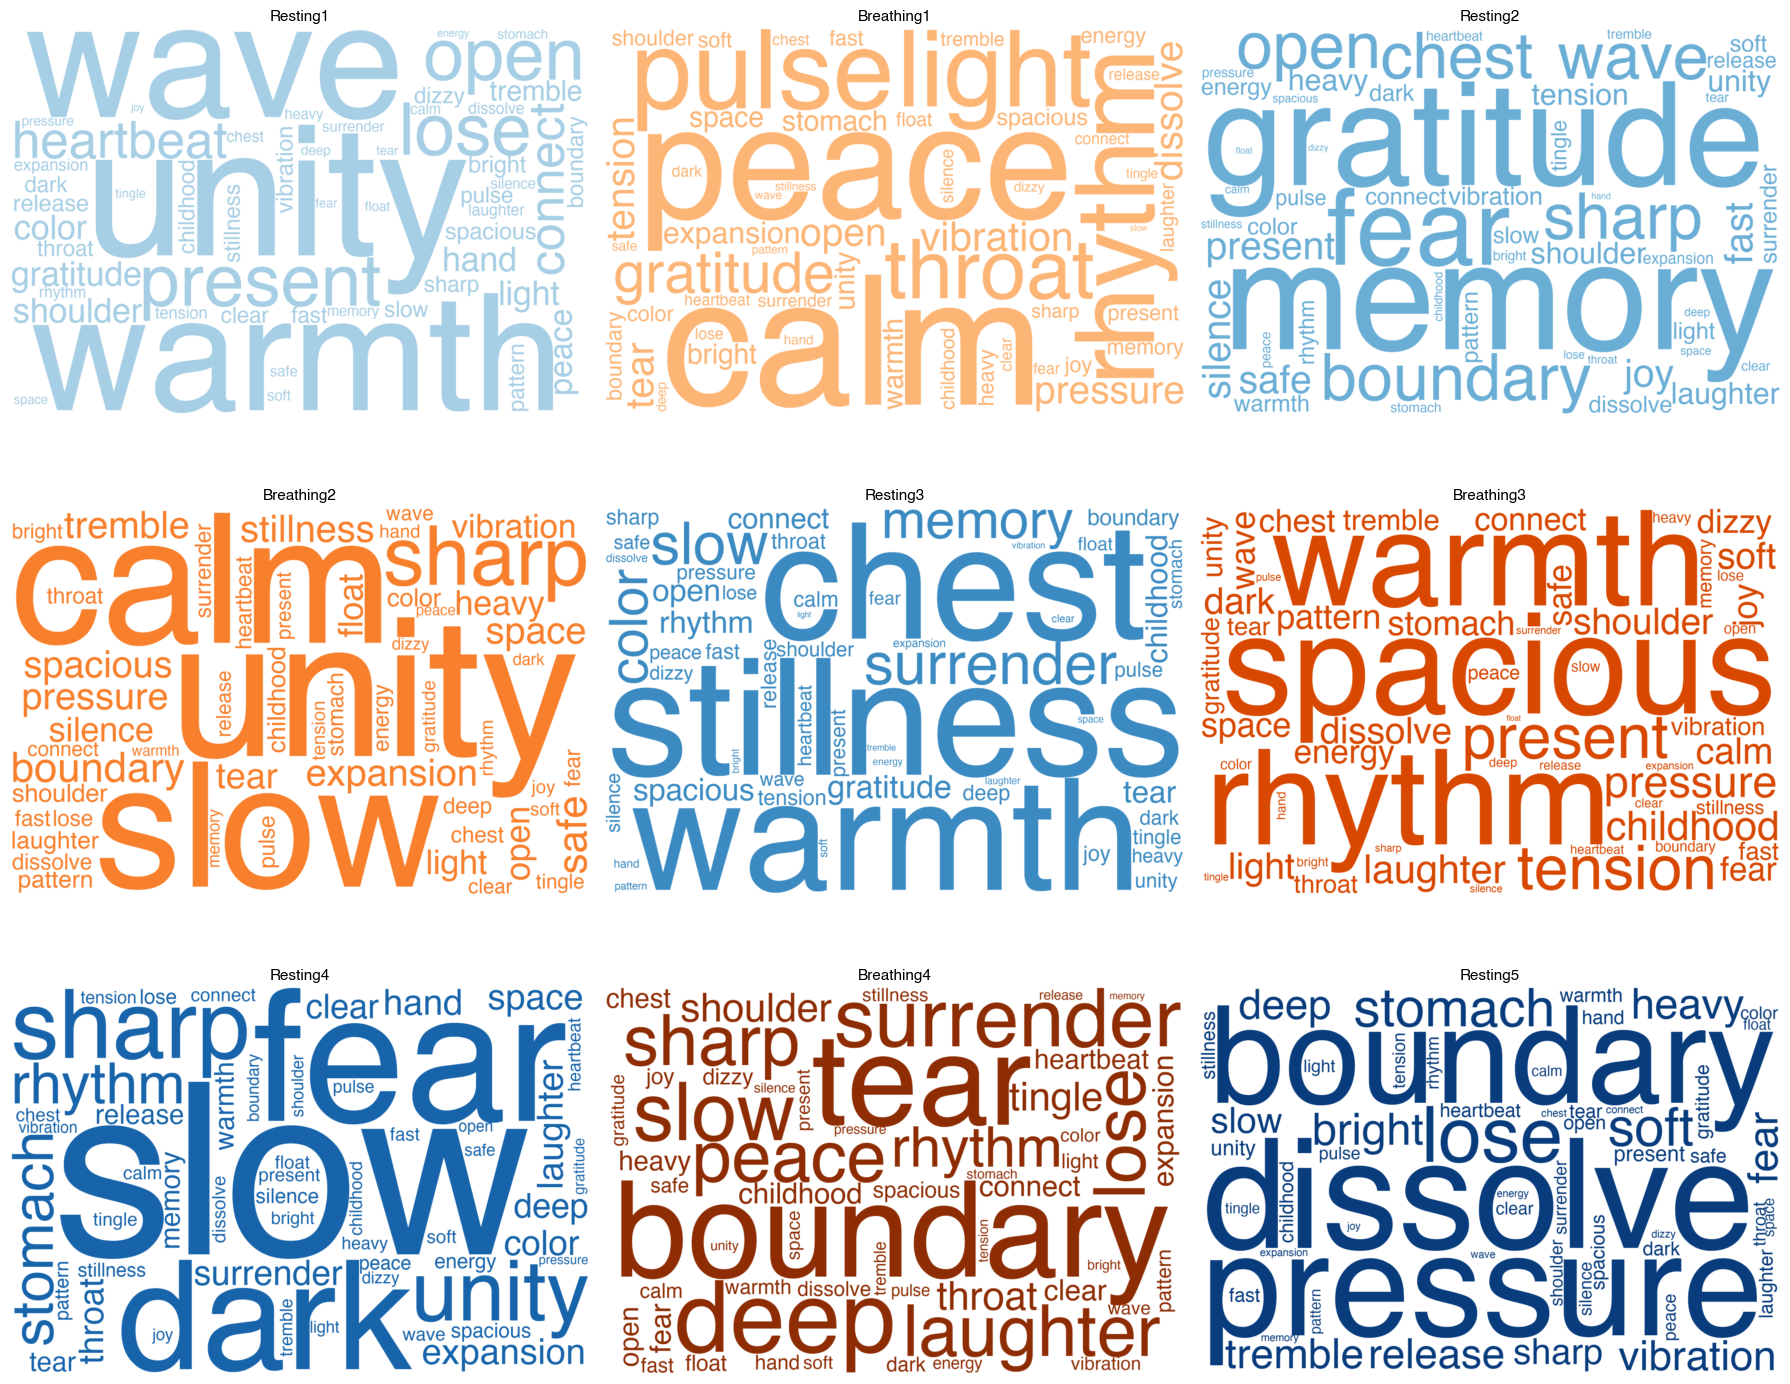

In [39]:
# --- Plot-A ---
EXCLUDE_QUALITY = {"timeless", "silence_detected"}            

sub = select_chunks(annot_ph, EXCLUDE_QUALITY, label="Plot A")
pc = phase_counter_for(sub)

ncols = 3
nrows = math.ceil(len(PHASES) / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 5 * nrows))
axes = np.atleast_1d(axes).ravel()
for p, ax in zip(PHASES, axes):
    make_cloud(pc[p], PHASE_CLOUD_COLORS[p], ax, p)
for ax in axes[len(PHASES):]:  
    ax.axis("off")
plt.tight_layout()
fig.savefig(OUT_DIR / f"wordclouds_phases_bw.svg")
plt.show()


## Load ASC data & prepare


In [40]:
asc = pd.read_csv(ASC_PATH)
asc = asc[asc["session"] == "BW"].copy()

asc["subject"] = norm_vp(asc["subject"])
asc = asc[~asc["subject"].isin(EXCLUDED_VPS)].copy()

valid_vps = annot["person_id"].unique()
asc = asc[asc["subject"].isin(valid_vps)].copy()

asc = asc.drop_duplicates("subject").reset_index(drop=True)

# Prepare MEQ Tertile Split (The only part needed for grouping the clouds)
def tertile_split(series: pd.Series) -> pd.Series:
    """Rank-based tertile groups ('low'/'mid'/'high'); equal-sized despite ties."""
    q = pd.qcut(series.rank(method="first"), 3, labels=["low", "mid", "high"])
    return q.astype(str)

# Apply the split
asc_meq = asc.set_index("subject")[["meq_total"]].dropna().copy()
asc_meq["group"] = tertile_split(asc_meq["meq_total"]) 

person_group = asc_meq["group"].to_dict()

# Diagnostic output
print(f"ASC BW VPs: {asc['subject'].nunique()}")
print(f"MEQ Total range: {asc['meq_total'].min():.2f} - {asc['meq_total'].max():.2f}")
print("Group breakdown:")
print(asc_meq["group"].value_counts().sort_index())

ASC BW VPs: 25
MEQ Total range: 0.22 - 0.72
Group breakdown:
group
high    9
low     8
mid     8
Name: count, dtype: int64


## Plot-B MEQ bins


[Plot 16] select_chunks: 208 chunks -> after exclude_quality 188 -> after require_filter_tag 188


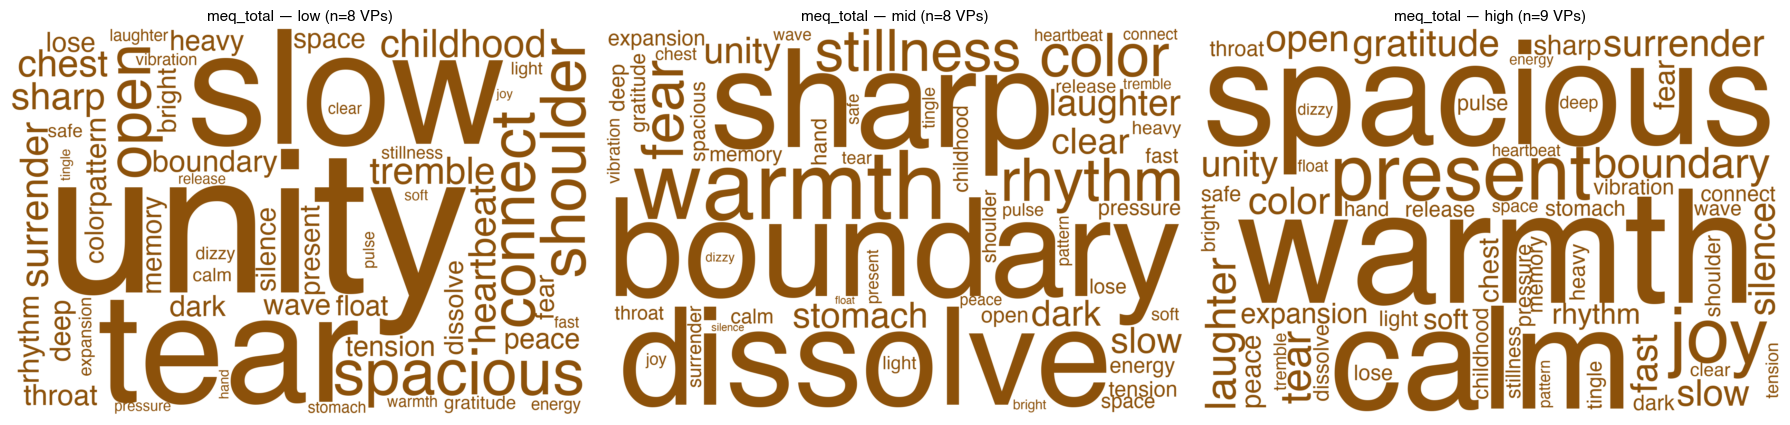

In [41]:
# --- Plot-B ---
EXCLUDE_QUALITY = {"silence_detected"}

sub = select_chunks(annot_ph, EXCLUDE_QUALITY, label="Plot 16")

GROUPS = ["low", "mid", "high"]

MEASURES = [("meq_total", MEQ_COLOR)]

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5)) 


for measure, color in MEASURES:
    v = pd.to_numeric(asc.set_index("subject")[measure], errors="coerce").dropna()
    grp = tertile_split(v)
    person_group = sub["person_id"].map(grp.to_dict())
    
    for col, g in enumerate(GROUPS):
        ax = axes[col]
        chunk_sub = sub[person_group == g]
        n_vp = chunk_sub["person_id"].nunique()
        make_cloud(pool_counter(chunk_sub), color, ax,
                   f"{measure} — {g} (n={n_vp} VPs)", max_words=100)

plt.tight_layout()
fig.savefig(OUT_DIR / f"wordclouds_meq_tertiles_bw.svg")
plt.show()